El objetivo de este proyecto es analizar los factores asociados al rendimiento de diferentes cultivos y desarrollar modelos para estimar el rendimiento agrícola a partir de variables ambientales, edáficas y de manejo. Cabe mencionar que el dataset es simulado con fines de entrenamiento.

The objective of this project is to analyze the factors associated with diferents crop yields and develop models to estime agricultural yield based on enviromental, soil and management variables. Should be noted that the dataset is simulated for training purposes

# **1.CARGA DE ARCHIVOS/ LOAD THE DATASET**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded= files.upload()

Saving agricultural_yield_dataset.csv to agricultural_yield_dataset.csv


# **2. EVALUACION DE CALIDAD DE DATOS/ INSPECT DATA QUALITY**

In [ ]:
df= pd.read_csv("agricultural_yield_dataset.csv")

In [ ]:
df.head()


,field_id,region,campaign,crop,soil_ph,organic_matter_pct,soil_moisture_pct,rainfall_mm,temperature_avg_c,fertilizer_kg_ha,irrigation,ndvi,gndvi,ndwi,savi,yield_tn_ha
0,L0001,Venado Tuerto,2025/26,Maíz,6.78,2.95,27.88,848.0,20.4,94.8,No,0.662,0.574,0.231,0.527,8.78
1,L0002,Pergamino,2024/25,Maíz,5.96,3.94,18.49,553.3,26.7,43.1,No,0.599,0.468,0.156,0.509,7.04
2,L0003,Marcos Juárez,2025/26,Trigo,5.07,3.25,21.03,350.0,24.9,94.8,Sí,0.496,0.467,0.134,0.394,2.63
3,L0004,Venado Tuerto,2025/26,Maíz,5.50,2.43,21.27,903.4,16.2,88.7,No,0.477,0.407,0.265,0.394,7.09
4,L0005,Ceres,2024/25,Soja,6.94,3.23,32.58,738.9,25.8,96.6,Sí,0.651,0.534,0.298,0.556,3.43


In [ ]:
df.shape

(1500, 16)

In [ ]:
df.columns

Index(['field_id', 'region', 'campaign', 'crop', 'soil_ph',
       'organic_matter_pct', 'soil_moisture_pct', 'rainfall_mm',
       'temperature_avg_c', 'fertilizer_kg_ha', 'irrigation', 'ndvi', 'gndvi',
       'ndwi', 'savi', 'yield_tn_ha'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   field_id            1500 non-null   object 
 1   region              1500 non-null   object 
 2   campaign            1500 non-null   object 
 3   crop                1500 non-null   object 
 4   soil_ph             1500 non-null   float64
 5   organic_matter_pct  1492 non-null   float64
 6   soil_moisture_pct   1492 non-null   float64
 7   rainfall_mm         1492 non-null   float64
 8   temperature_avg_c   1500 non-null   float64
 9   fertilizer_kg_ha    1500 non-null   float64
 10  irrigation          1500 non-null   object 
 11  ndvi                1492 non-null   float64
 12  gndvi               1500 non-null   float64
 13  ndwi                1500 non-null   float64
 14  savi                1500 non-null   float64
 15  yield_tn_ha         1500 non-null   float64
dtypes: flo

In [ ]:
df.describe()

,soil_ph,organic_matter_pct,soil_moisture_pct,rainfall_mm,temperature_avg_c,fertilizer_kg_ha,ndvi,gndvi,ndwi,savi,yield_tn_ha
count,1500.000000,1492.000000,1492.000000,1492.000000,1500.000000,1500.000000,1492.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,6.303040,2.716421,28.034698,718.728954,21.344000,124.688667,0.642030,0.561947,0.249116,0.538869,5.314647
std,0.443206,0.646840,6.041785,165.150903,3.255557,44.594164,0.080345,0.087220,0.052817,0.076337,2.145283
min,5.060000,1.000000,12.000000,350.000000,14.000000,20.000000,0.333000,0.261000,0.105000,0.274000,1.650000
25%,5.990000,2.270000,24.105000,610.575000,19.100000,94.475000,0.588000,0.506000,0.215000,0.487000,3.520000
50%,6.295000,2.720000,27.705000,717.200000,21.300000,124.400000,0.642000,0.562000,0.248500,0.539000,4.355000
75%,6.590000,3.132500,32.180000,830.575000,23.500000,155.100000,0.697000,0.619000,0.285250,0.590250,7.652500
max,7.600000,4.810000,45.000000,1200.000000,30.000000,250.000000,0.898000,0.846000,0.436000,0.783000,9.770000


Para la variable de interes "yield_tn_ha" se observa una media de 5.31 y una mediana de 4.35 lo que indicaria de manera preliminar una distribucion asimetrica o presencia de outliers.

For the target variable "yield_tn_ha" a mean of 5.31 and a median of 4.35 are observed, wich would preliminarily indicates an asymmetric distribution and presence of outliers.

Variables como rainfall_mm y NDVI presentan medias y medianas similares lo que indicaria distribuciones uniformes.

Variables such as "rainfall_mm" and "NDVI" presents similar means and medians that indicates simmetric distributions.

# **3.ANALISIS EXPLORATORIO DE DATOS/EXPLORATORY DATA ANALYSIS (EDA)**

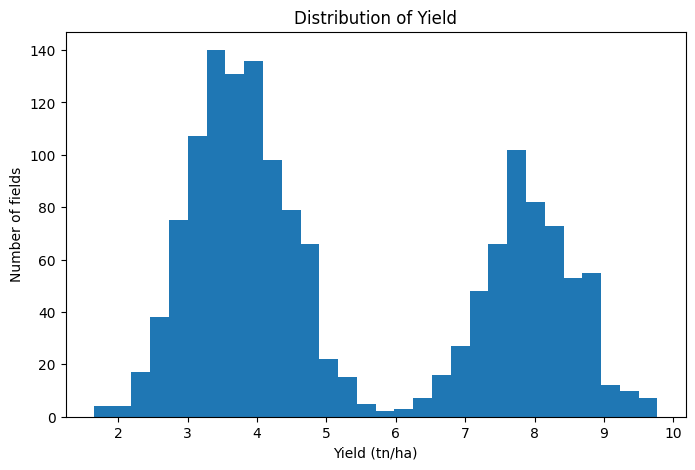

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["yield_tn_ha"], bins=30)

plt.xlabel("Yield (tn/ha)")
plt.ylabel("Number of fields")
plt.title("Distribution of Yield")

plt.show()

Se presentan dos grupos de rendimientos.

Two groups of yields are presented.

In [ ]:
df["crop"].value_counts()


,count
crop,
Soja,631
Maíz,562
Trigo,307


In [ ]:
df["crop"].value_counts(normalize=True)*100

,proportion
crop,
Soja,42.066667
Maíz,37.466667
Trigo,20.466667


In [ ]:
df.groupby("crop")["yield_tn_ha"].describe()

,count,mean,std,min,25%,50%,75%,max
crop,,,,,,,,
Maíz,562.0,7.938648,0.673506,5.70,7.4825,7.915,8.3975,9.77
Soja,631.0,3.612203,0.664200,1.65,3.1450,3.600,4.0700,5.49
Trigo,307.0,4.010261,0.689779,2.36,3.4950,3.990,4.5800,5.98


<Figure size 800x500 with 0 Axes>

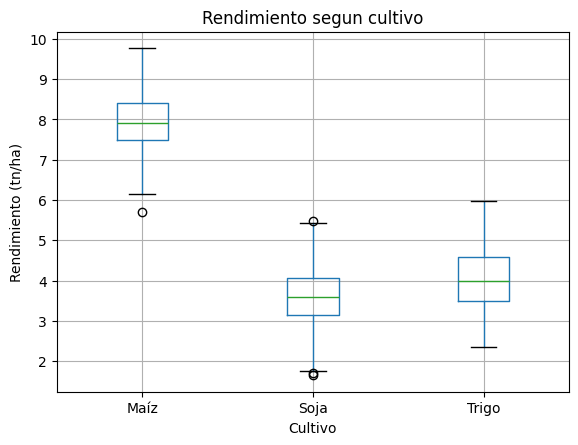

In [ ]:
plt.figure(figsize=(8,5))

df.boxplot(
    column="yield_tn_ha",
    by="crop",
)

plt.xlabel("Cultivo")
plt.ylabel("Rendimiento (tn/ha)")
plt.title("Rendimiento segun cultivo")
plt.suptitle("")

plt.show()


El rendimiento presenta notorias diferencias entre el cultivo de maiz y los demas, con una mediana mayor (7,9 t/ha) mientras que soja y trigo presentan medianas mucho menores (3,6 y 4 t/ha). La dispersion del 50% central de los datos es similar entre maiz y soja mientras que el trigo presenta un IQR mayor. Se identifican valores atipicos en cultivos de soja y maiz

Yields presents notable differences between corn and the others corps,with a higher median (7,9 t/ha) while soy and wheat presents lower medians (3,6 y  4 t/ha). The dispersion of the central 50% of the data is similar between corn and soy besides wheat presents higher IQR. Soy and corn shows outliers.

In [ ]:
correlation= df.select_dtypes(include=["number"]).corr()
correlation["yield_tn_ha"].sort_values(ascending= False)

,yield_tn_ha
yield_tn_ha,1.000000
rainfall_mm,0.192194
ndvi,0.145341
gndvi,0.131317
savi,0.115642
soil_moisture_pct,0.111668
fertilizer_kg_ha,0.091274
organic_matter_pct,0.063141
ndwi,0.052593
soil_ph,-0.013882


In [ ]:
correlation["yield_tn_ha"]

,yield_tn_ha
soil_ph,-0.013882
organic_matter_pct,0.063141
soil_moisture_pct,0.111668
rainfall_mm,0.192194
temperature_avg_c,-0.042850
fertilizer_kg_ha,0.091274
ndvi,0.145341
gndvi,0.131317
ndwi,0.052593
savi,0.115642


In [ ]:
correlation["yield_tn_ha"].sort_values(ascending= False)

,yield_tn_ha
yield_tn_ha,1.000000
rainfall_mm,0.192194
ndvi,0.145341
gndvi,0.131317
savi,0.115642
soil_moisture_pct,0.111668
fertilizer_kg_ha,0.091274
organic_matter_pct,0.063141
ndwi,0.052593
soil_ph,-0.013882


Analizando correlaciones de todas las variables respecto a los tres cultivos podemos concluir que las variables no presentan fuertes asociaciones positivas con el rendimiento.

Analyzing correlations of all variables with respect to the three crops, we can conclude that the vairables do not present high positive associations with yield

In [ ]:
df.groupby("crop")[[
    "rainfall_mm",
    "fertilizer_kg_ha",
    "ndvi",
    "temperature_avg_c",
    "soil_moisture_pct",
    "yield_tn_ha"
]].corr()["yield_tn_ha"]

crop                    
Maíz   rainfall_mm          0.486504
       fertilizer_kg_ha     0.210930
       ndvi                 0.509161
       temperature_avg_c    0.034209
       soil_moisture_pct    0.271732
       yield_tn_ha          1.000000
Soja   rainfall_mm          0.431666
       fertilizer_kg_ha     0.105922
       ndvi                 0.410052
       temperature_avg_c   -0.050539
       soil_moisture_pct    0.323198
       yield_tn_ha          1.000000
Trigo  rainfall_mm          0.533285
       fertilizer_kg_ha     0.178972
       ndvi                 0.506844
       temperature_avg_c    0.003768
       soil_moisture_pct    0.265212
       yield_tn_ha          1.000000
Name: yield_tn_ha, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

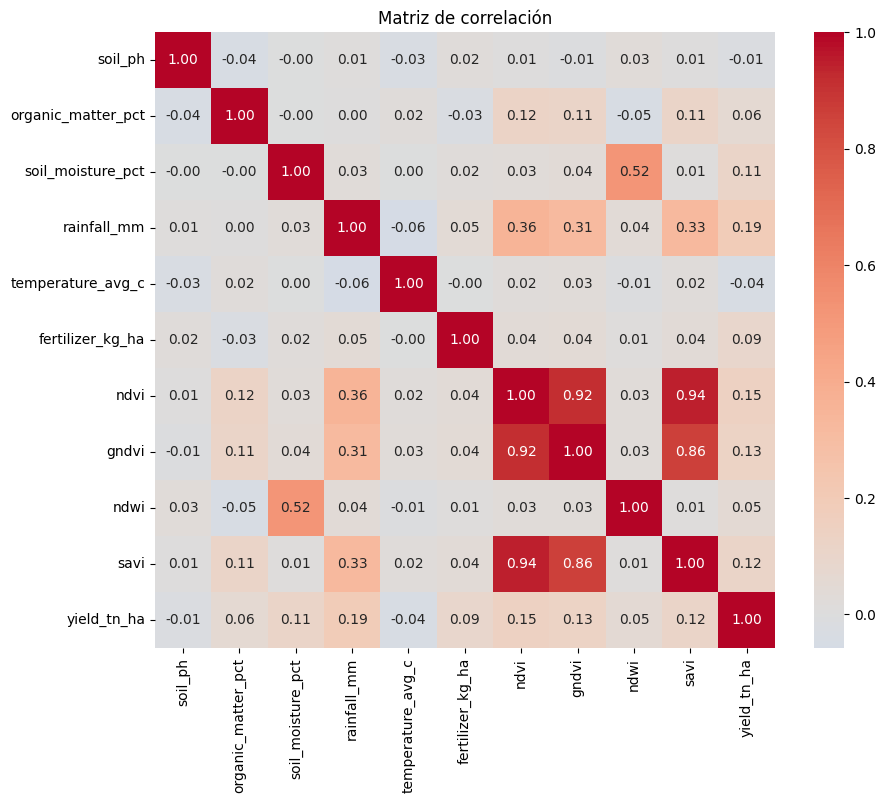

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt= ".2f",
    center=0
)

plt.title("Matriz de correlación")
plt.show

Se observa multicolinealidad entre variables relacionadas entre si; savi gndvi y ndvi. Para analisis predictivos seria redundante tener en cuenta a las tres. Se observa ademas fuerte asociacion entre humedad del suelo y ndvi. Tambien se presenta asociacion entre mm de lluvia, ndvi y savi.

Multicollinearity is observed between related variables; savi, gndvi and ndvi. For predictive analyisis, consider all three would be redundant. Also there is a strog association among soil moisture and ndvi. Furthermore, an association is found between rainfall (mm), ndvi, and savi.

Por separado podemos destacar que los rendimientos de los tres cultivos se ven afectados por tres variables principalmente que presentan asociacion positiva moderada: NDVI, mm de precipitacion y humedad del suelo en menor proporcion.

Evaluating the corps separately we can highlight that the yields are affected by three variables with moderated positive association; ndvi, rainfall (mm) and soil moisture.

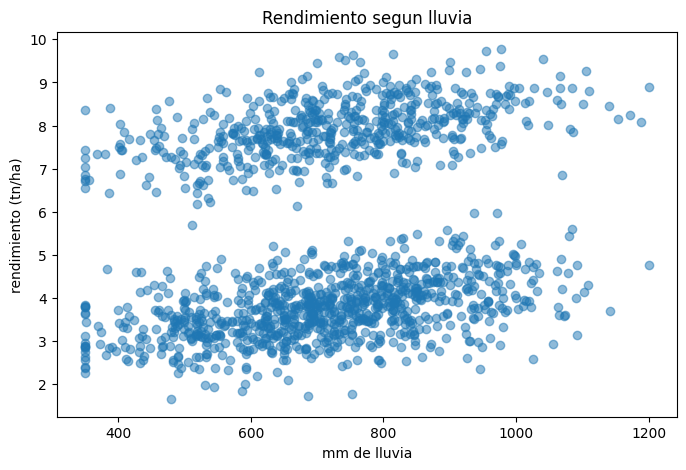

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["rainfall_mm"],
    df["yield_tn_ha"],
    alpha=0.5

)

plt.xlabel("mm de lluvia")
plt.ylabel("rendimiento (tn/ha)")
plt.title("Rendimiento segun lluvia")

plt.show()

Como era esperable de acuerdo al resultado del histograma se observan dos grupos. Ambos presentan una tendencia positiva (a medida que aumentan los mm de lluvia, aumenta el rendimiento) pero cabe destacar que la asociacion entre estas dos variables era baja entonces podemos suponer que estos dos grupos se dan por la diferencia de rendimientos que presenta maiz respectoa soja y trigo.

As expected based on the histogram results, two groups are observed. Both show a positive trend (as rainfall increases, yield increases), but it's important to mention that the association between these two variables were low so we can assume that these two groups arise from the difference in yields between corn and soy and wheat

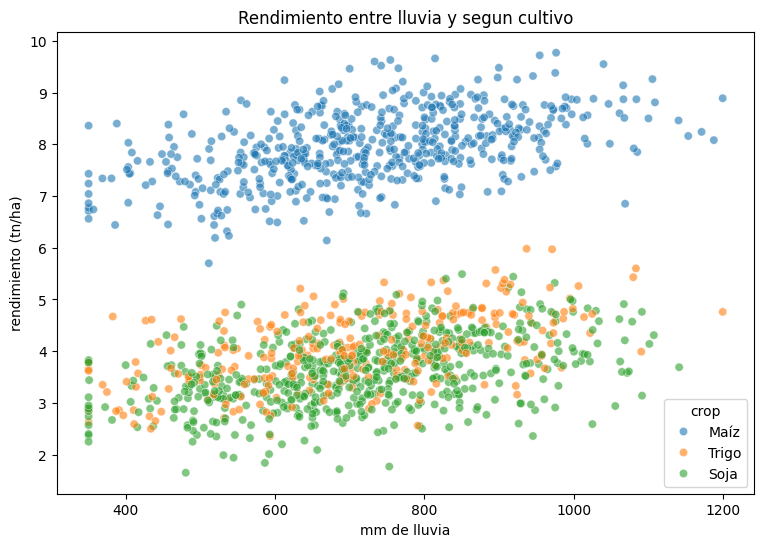

In [ ]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="rainfall_mm",
    y="yield_tn_ha",
    hue="crop",
    alpha=0.6
)
plt.xlabel("mm de lluvia")
plt.ylabel("rendimiento (tn/ha)")
plt.title("Rendimiento entre lluvia y segun cultivo")

plt.show()

Se comprueba la hipotesis anterior que la agrupacion de datos se debe a la diferencia en el rendimiento del maiz.

The hypothesis that the data clustering is due to differences in corn yields is confirmed.

Es importante ademas tener en cuenta la dispersion de los puntos en el grafico, lo que indica que hay otras variables involucradas en la variacion del rendimiento.

It is also important to mention the dispersion of the points in plot, wich indicates that there are other variables involved in the yield variations.

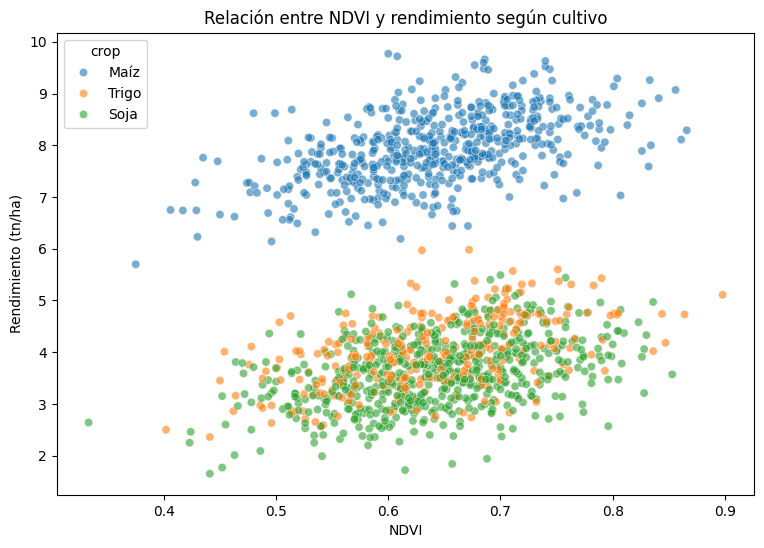

In [ ]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="ndvi",
    y="yield_tn_ha",
    hue="crop",
    alpha=0.6
)

plt.xlabel("NDVI")
plt.ylabel("Rendimiento (tn/ha)")
plt.title("Relación entre NDVI y rendimiento según cultivo")

plt.show()

NDVI también presenta una asociación positiva moderada con el rendimiento, especialmente en maíz y trigo.

NDVI shows a moderated positive association with yield, specially in corn and wheat.

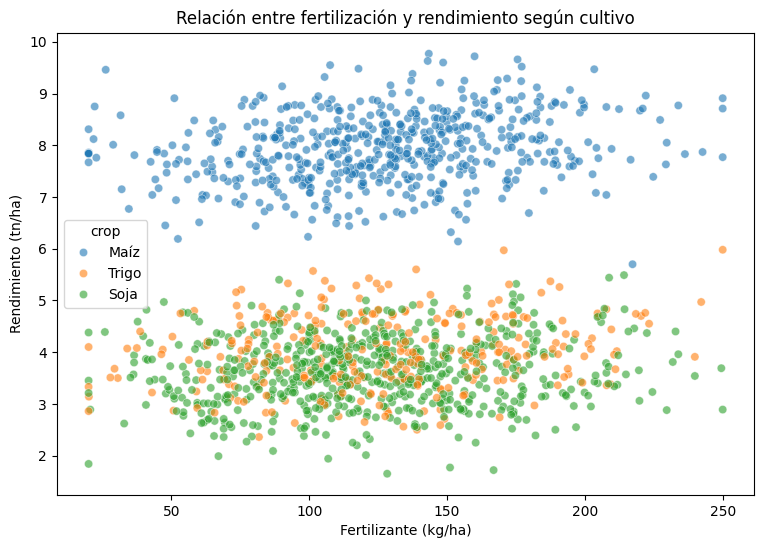

In [ ]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="fertilizer_kg_ha",
    y="yield_tn_ha",
    hue="crop",
    alpha=0.6
)

plt.xlabel("Fertilizante (kg/ha)")
plt.ylabel("Rendimiento (tn/ha)")
plt.title("Relación entre fertilización y rendimiento según cultivo")

plt.show()

La cantidad de fertilizante presenta una asociación lineal positiva débil con el rendimiento


The amount of fertilizer shows a weak positive linear association with yield

# **4.PREPARACION DE DATOS/PREPARE FEATURES AND TARGET**


In [ ]:
df.isnull().sum()

,0
field_id,0
region,0
campaign,0
crop,0
soil_ph,0
organic_matter_pct,8
soil_moisture_pct,8
rainfall_mm,8
temperature_avg_c,0
fertilizer_kg_ha,0


In [ ]:
missing = df.isnull().sum()
missing_percentage = (missing/len(df))*100

missing_table =pd.DataFrame({
    "missing_values": missing,
    "percentage": missing_percentage
})
missing_table

,missing_values,percentage
field_id,0,0.000000
region,0,0.000000
campaign,0,0.000000
crop,0,0.000000
soil_ph,0,0.000000
organic_matter_pct,8,0.533333
soil_moisture_pct,8,0.533333
rainfall_mm,8,0.533333
temperature_avg_c,0,0.000000
fertilizer_kg_ha,0,0.000000


Solo cuatro variables presentan valores faltantes, y de cada variable se tienen 8 valores faltantes (0.53% total de cada una)

There are only four variables have missing values, and each variable contains eight missing values (0.53% of the total)

In [ ]:
df["has_missing"]=df.isnull().any(axis=1)

In [ ]:
df["has_missing"].value_counts()

,count
has_missing,
False,1468
True,32


In [ ]:
df[df["has_missing"]]

,field_id,region,campaign,crop,soil_ph,organic_matter_pct,soil_moisture_pct,rainfall_mm,temperature_avg_c,fertilizer_kg_ha,irrigation,ndvi,gndvi,ndwi,savi,yield_tn_ha,has_missing
25,L0026,Esperanza,2024/25,Soja,6.38,NaN,19.31,610.6,20.9,171.6,No,0.804,0.678,0.177,0.716,4.41,True
70,L0071,Venado Tuerto,2023/24,Soja,5.60,NaN,31.64,710.7,17.8,112.5,No,0.653,0.543,0.210,0.536,3.67,True
129,L0130,Esperanza,2025/26,Maíz,7.41,2.91,28.93,NaN,22.9,92.8,No,0.632,0.570,0.279,0.549,7.57,True
141,L0142,Ceres,2023/24,Maíz,6.87,3.38,28.48,NaN,19.7,58.3,No,0.624,0.586,0.316,0.513,8.48,True
226,L0227,Ceres,2024/25,Soja,5.99,2.09,NaN,759.2,25.6,138.6,No,0.705,0.573,0.293,0.607,3.91,True
250,L0251,Ceres,2023/24,Maíz,6.55,2.30,NaN,403.1,26.5,157.4,No,0.511,0.477,0.255,0.433,6.87,True
261,L0262,Marcos Juárez,2023/24,Trigo,6.25,2.62,25.27,859.1,15.5,123.8,No,NaN,0.443,0.281,0.418,4.74,True
297,L0298,Ceres,2025/26,Trigo,6.10,2.60,28.06,NaN,22.9,30.6,No,0.639,0.514,0.183,0.542,3.50,True
333,L0334,Rafaela,2025/26,Trigo,5.06,2.06,30.57,814.2,15.0,140.7,No,NaN,0.620,0.278,0.600,3.73,True
445,L0446,Venado Tuerto,2024/25,Maíz,5.87,3.04,29.94,581.8,27.8,144.4,No,NaN,0.391,0.340,0.417,7.65,True


In [ ]:
df.columns



Index(['field_id', 'region', 'campaign', 'crop', 'soil_ph',
       'organic_matter_pct', 'soil_moisture_pct', 'rainfall_mm',
       'temperature_avg_c', 'fertilizer_kg_ha', 'irrigation', 'ndvi', 'gndvi',
       'ndwi', 'savi', 'yield_tn_ha', 'has_missing'],
      dtype='object')

In [ ]:
X = df.drop(columns="yield_tn_ha")
y = df["yield_tn_ha"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Dimensiones de X: (1500, 16)
Dimensiones de y: (1500,)


In [ ]:
print("Variables categóricas:")
print(X.select_dtypes(include="object").columns)

print("\nVariables numéricas:")
print(X.select_dtypes(include="number").columns)

Variables categóricas:
Index(['field_id', 'region', 'campaign', 'crop', 'irrigation'], dtype='object')

Variables numéricas:
Index(['soil_ph', 'organic_matter_pct', 'soil_moisture_pct', 'rainfall_mm',
       'temperature_avg_c', 'fertilizer_kg_ha', 'ndvi', 'gndvi', 'ndwi',
       'savi'],
      dtype='object')


In [ ]:
print("\nValores faltantes:")
print(X.isnull().sum())


Valores faltantes:
field_id              0
region                0
campaign              0
crop                  0
soil_ph               0
organic_matter_pct    8
soil_moisture_pct     8
rainfall_mm           8
temperature_avg_c     0
fertilizer_kg_ha      0
irrigation            0
ndvi                  8
gndvi                 0
ndwi                  0
savi                  0
has_missing           0
dtype: int64


La variable field_id no es una variable agronomica por lo que podemos eliminarla para evitar errores.

The variables "field_id" is not an agronomic variable so we can delete it.

In [ ]:
X = X.drop(columns="field_id")

print(X.shape)

(1500, 15)


In [ ]:
X = df.drop(columns=["yield_tn_ha", "field_id", "has_missing"])
y = df["yield_tn_ha"]

print("X:", X.shape)
print("y:", y.shape)

X: (1500, 14)
y: (1500,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (1200, 14)
X_test: (300, 14)
y_train: (1200,)
y_test: (300,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


Reemplazamos los valores faltantes por la mediana en caso de variables numericas, en caso de variables categoricas reemplazamos los faltantes por la categoria mas frecuente.

Replace the missing values with the median in the case of numerical variables, for categorical variables we replace the missing values with the most frequent category



## **5.PIPELINE DE PREPROCESAMIENTO/PREPROCESSING PIPELINE**

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
numeric_features = [
    "soil_ph",
    "organic_matter_pct",
    "soil_moisture_pct",
    "rainfall_mm",
    "temperature_avg_c",
    "fertilizer_kg_ha",
    "ndvi",
    "gndvi",
    "ndwi",
    "savi"
]

In [ ]:
categorical_features = [
    "region",
    "campaign",
    "crop",
    "irrigation"
]

In [ ]:
print("Variables numéricas:")
print(numeric_features)

print("\nVariables categóricas:")
print(categorical_features)

Variables numéricas:
['soil_ph', 'organic_matter_pct', 'soil_moisture_pct', 'rainfall_mm', 'temperature_avg_c', 'fertilizer_kg_ha', 'ndvi', 'gndvi', 'ndwi', 'savi']

Variables categóricas:
['region', 'campaign', 'crop', 'irrigation']


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# **6. ENTRENAMIENTO Y EVALUACION DE MODELO/ TRAIN AND EVALUATE MODEL**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [ ]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [ ]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['soil_ph',
                                                   'organic_matter_pct',
                                                   'soil_moisture_pct',
                                                   'rainfall_mm',
                                                   'temperature_avg_c',
                                                   'fertilizer_kg_ha', 'ndvi',
                                                   'gndvi', 'ndwi', 'savi']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['region', 'campaign', 'crop',
                                                   'irrigation'])])),
                ('regressor', LinearRegression())])

In [ ]:
y_pred = linear_model.predict(X_test)

# **7. CROSS-VALIDATION**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.3684157954843559
RMSE: 0.47369964279727605
R²: 0.9509893908492982


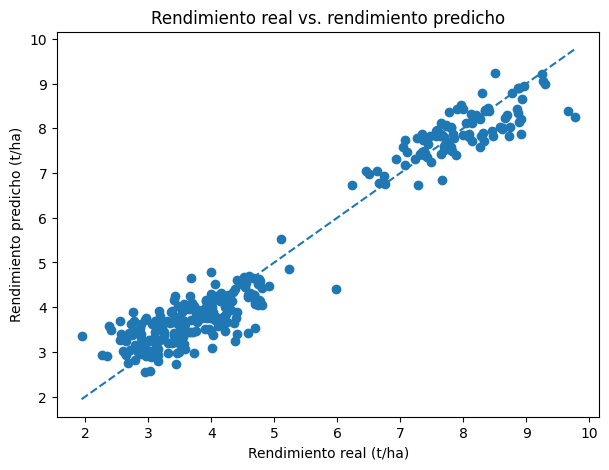

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Rendimiento real (t/ha)")
plt.ylabel("Rendimiento predicho (t/ha)")
plt.title("Rendimiento real vs. rendimiento predicho")

plt.show()

# **8.RANDOM FOREST**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['soil_ph',
                                                   'organic_matter_pct',
                                                   'soil_moisture_pct',
                                                   'rainfall_mm',
                                                   'temperature_avg_c',
                                                   'fertilizer_kg_ha', 'ndvi',
                                                   'gndvi', 'ndwi', 'savi']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['region', 'campaign', 'crop',
                                                   'irrigation'])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [ ]:
y_pred_rf = rf_model.predict(X_test)
print(y_pred_rf[:10])

[4.12865 3.2304  3.3272  4.2257  3.4319  8.6827  8.23075 4.2686  3.3619
 7.3092 ]


In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

MAE: 0.42251700000000003
RMSE: 0.5277009927032543
R²: 0.939178124453636


In [ ]:
from sklearn.model_selection import cross_validate

In [ ]:
cv_linear= cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "MAE":"neg_mean_absolute_error",
        "RMSE":"neg_root_mean_squared_error",
        "R2":"r2"
        }
)



In [ ]:
print("Linear Regression")
print("MAE:", -cv_linear["test_MAE"].mean())
print("RMSE:", -cv_linear["test_RMSE"].mean())
print("R2:", cv_linear["test_R2"].mean())

Linear Regression
MAE: 0.3895927042689099
RMSE: 0.48021210539338055
R2: 0.9492944644738607


In [ ]:
cv_rf = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }
)

In [ ]:
print("Random Forest")
print("MAE:", -cv_rf["test_MAE"].mean())
print("RMSE:", -cv_rf["test_RMSE"].mean())
print("R²:", cv_rf["test_R2"].mean())

Random Forest
MAE: 0.42080845833333314
RMSE: 0.5212625893916205
R²: 0.9402011986098155


In [ ]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

print(feature_names)

['num__soil_ph' 'num__organic_matter_pct' 'num__soil_moisture_pct'
 'num__rainfall_mm' 'num__temperature_avg_c' 'num__fertilizer_kg_ha'
 'num__ndvi' 'num__gndvi' 'num__ndwi' 'num__savi' 'cat__region_Ceres'
 'cat__region_Esperanza' 'cat__region_Marcos Juárez'
 'cat__region_Pergamino' 'cat__region_Rafaela' 'cat__region_Venado Tuerto'
 'cat__campaign_2022/23' 'cat__campaign_2023/24' 'cat__campaign_2024/25'
 'cat__campaign_2025/26' 'cat__crop_Maíz' 'cat__crop_Soja'
 'cat__crop_Trigo' 'cat__irrigation_No' 'cat__irrigation_Sí']


In [ ]:
importances = rf_model.named_steps["regressor"].feature_importances_

print(importances)

[3.99258482e-03 8.34362666e-03 1.14933534e-02 2.12943472e-02
 5.72519777e-03 6.05266029e-03 1.65196986e-02 5.05114177e-03
 4.43553232e-03 8.25928819e-03 4.86481015e-04 4.53848041e-04
 4.41428024e-04 4.29302950e-04 4.45643186e-04 4.67590552e-04
 5.59752061e-04 4.76240266e-04 4.61149651e-04 5.65907325e-04
 8.98215491e-01 1.14858249e-03 1.06940485e-03 1.90770358e-03
 1.70404372e-03]


In [ ]:
import pandas as pd

importance_df = pd.DataFrame({
    "variable": feature_names,
    "importance": importances
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

importance_df.head(10)

,variable,importance
20,cat__crop_Maíz,0.898215
3,num__rainfall_mm,0.021294
6,num__ndvi,0.016520
2,num__soil_moisture_pct,0.011493
1,num__organic_matter_pct,0.008344
9,num__savi,0.008259
5,num__fertilizer_kg_ha,0.006053
4,num__temperature_avg_c,0.005725
7,num__gndvi,0.005051
8,num__ndwi,0.004436


Dentro de este modelo, crop_Maíz fue la variable transformada con mayor importancia para las predicciones.

In this model, the variable "crop_maiz" was the most important transformed variable

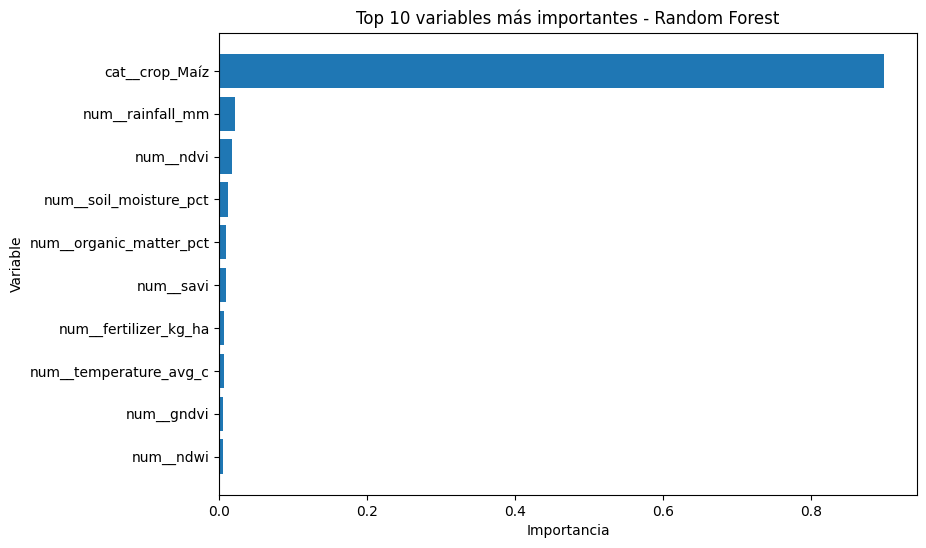

In [ ]:
top10 = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(9, 6))

plt.barh(top10["variable"], top10["importance"])

plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Top 10 variables más importantes - Random Forest")

plt.show()

# **9.PERMUTATION IMPORTANCE**

In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
perm_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

In [ ]:
perm_df = pd.DataFrame({
    "variable": X_test.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std
})

perm_df = perm_df.sort_values(
    "importance_mean",
    ascending=False
)

perm_df

,variable,importance_mean,importance_std
2,crop,1.703345,0.101376
6,rainfall_mm,0.020390,0.002882
5,soil_moisture_pct,0.010330,0.001464
10,ndvi,0.005257,0.002561
4,organic_matter_pct,0.004723,0.001411
8,fertilizer_kg_ha,0.002424,0.000652
9,irrigation,0.001585,0.000861
7,temperature_avg_c,0.001557,0.000835
0,region,0.000226,0.000228
12,ndwi,-0.000100,0.000575


La Permutation Importance mostró que el cultivo fue la variable con mayor impacto sobre el rendimiento predictivo del modelo. Entre las variables numéricas, la precipitación y la humedad del suelo presentaron las mayores contribuciones, seguidas por NDVI y materia orgánica. Las variables de vegetación altamente correlacionadas, como GNDVI y SAVI, mostraron una importancia marginal, lo que puede estar relacionado con la redundancia de información entre índices.

Permutation Importance showed that crop was the variable with the greatest impact on the model's predictive performance. Among the numerical variables, precipitation and soil moisture made the largest contributions, followed by NDVI and organic matter. Highly correlated vegetation variables, such as GNDVI and SAVI, showed marginal importance, which may be related to redundancy of information among indices.

# **10.ANALISIS DE ERRORES/ ERROR ANALYSIS**

In [ ]:
errores_df = pd.DataFrame({
    "real": y_test,
    "predicho": y_pred_rf
})

errores_df["error"] = (
    errores_df["real"] - errores_df["predicho"]
)

errores_df["error_absoluto"] = (
    errores_df["error"].abs()
)

errores_df.head(10)

,real,predicho,error,error_absoluto
1116,4.78,4.12865,0.65135,0.65135
1368,2.63,3.23040,-0.60040,0.60040
422,3.25,3.32720,-0.07720,0.07720
413,4.80,4.22570,0.57430,0.57430
451,3.97,3.43190,0.53810,0.53810
861,8.94,8.68270,0.25730,0.25730
1063,8.58,8.23075,0.34925,0.34925
741,4.68,4.26860,0.41140,0.41140
1272,3.12,3.36190,-0.24190,0.24190
259,7.08,7.30920,-0.22920,0.22920


In [ ]:
errores_df.sort_values(
    "error_absoluto",
    ascending=False
).head(10)

,real,predicho,error,error_absoluto
629,5.98,4.00380,1.97620,1.97620
765,1.94,3.59140,-1.65140,1.65140
706,9.77,8.25725,1.51275,1.51275
81,2.77,4.18390,-1.41390,1.41390
1232,2.40,3.74625,-1.34625,1.34625
218,4.01,2.86095,1.14905,1.14905
51,2.57,3.71720,-1.14720,1.14720
1448,8.91,7.76590,1.14410,1.14410
203,2.59,3.73270,-1.14270,1.14270
792,2.55,3.68640,-1.13640,1.13640


In [ ]:
errores_df["crop"] = X_test["crop"].values

errores_df.groupby("crop").agg(
    MAE=("error_absoluto", "mean"),
    error_medio=("error", "mean"),
    cantidad=("error", "count")
).sort_values("MAE", ascending=False)

,MAE,error_medio,cantidad
crop,,,
Trigo,0.444508,0.296232,60
Soja,0.430840,-0.209344,141
Maíz,0.397335,0.023008,99


El modelo tiene un rendimiento relativamente similar entre los tres cultivos, aunque el trigo presenta el mayor error absoluto promedio. También parece existir una tendencia a subestimar el trigo y sobreestimar la soja.

The model performs relatively similarly across the three crops, although wheat shows the highest average absolute error. There also appears to be a tendency to underestimate wheat and overestimate soybeans.

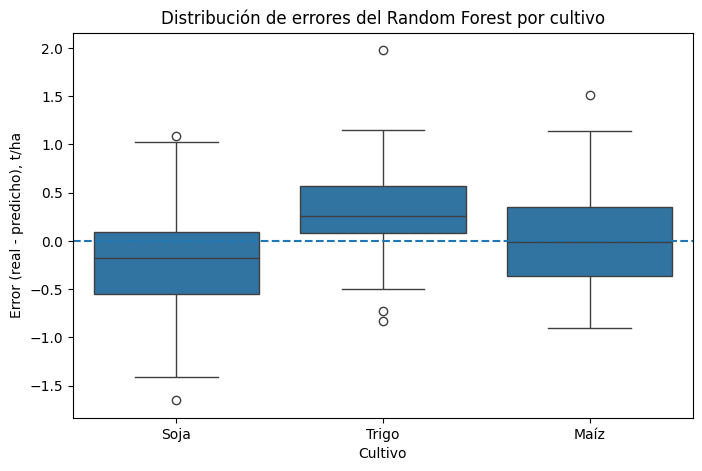

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=errores_df,
    x="crop",
    y="error"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Cultivo")
plt.ylabel("Error (real - predicho), t/ha")
plt.title("Distribución de errores del Random Forest por cultivo")

plt.show()

Soja: La mediana está por debajo de cero por lo que el modelo tiende a sobreestimar el rendimiento, la caja se extiende a ambos lados de cero, lo que muestra que también hay subestimaciones. Además aparece un valor atípico.
Trigo: La mediana está por encima de cero, es decir, el modelo tiende a subestimar el rendimiento, a mayoría de los errores centrales son positivos y tiene un valor atípico cercano a 1,98 t/ha, que coincide con uno de los mayores errores que identificamos anteriormente.
Maíz: la mediana está muy cerca de cero, los errores están distribuidos a ambos lados de la línea, sin un sesgo central tan evidente como en los otros cultivos. Se observa un error positivo de aproximadamente +1,51 t/ha.

Soybeans: The median is below zero, so the model tends to overestimate yield. The box extends on both sides of zero, showing that there are also underestimations. An outlier is also present.
Wheat: The median is above zero, meaning the model tends to underestimate yield. Most of the central errors are positive, and there is an outlier close to 1.98 t/ha, which coincides with one of the largest errors identified earlier.
Corn: The median is very close to zero. The errors are distributed on both sides of the line, without as evident a central bias as in the other crops. A positive error of approximately +1.51 t/ha is observed.

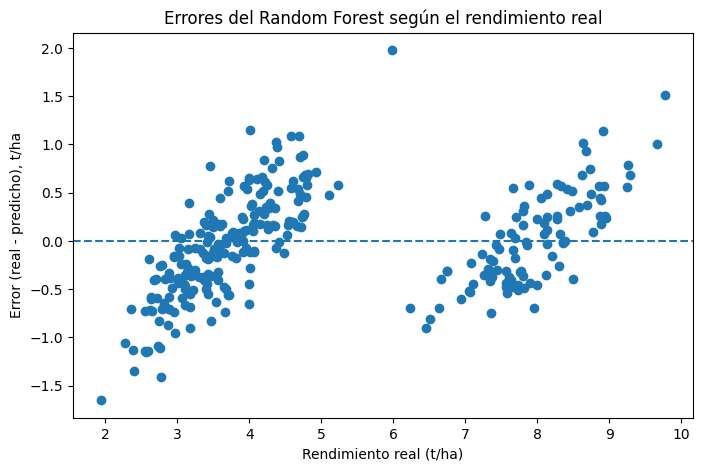

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    errores_df["real"],
    errores_df["error"]
)

plt.axhline(0, linestyle="--")

plt.xlabel("Rendimiento real (t/ha)")
plt.ylabel("Error (real - predicho), t/ha")
plt.title("Errores del Random Forest según el rendimiento real")

plt.show()

# **11.CONCLUSIONES/CONCLUSIONS**

El análisis permitió identificar que el rendimiento agrícola está asociado a múltiples factores, entre ellos las precipitaciones, la humedad del suelo, los índices de vegetación y, especialmente, el tipo de cultivo. Este último aspecto es fundamental para interpretar correctamente los resultados, ya que un mismo rendimiento por hectárea no tiene el mismo significado productivo para todos los cultivos. Por ejemplo, un rendimiento de 20 quintales por hectárea puede considerarse favorable en maíz, mientras que en soja podría resultar bajo, dependiendo de las condiciones de producción y de la región. En soja, un rendimiento de 30 a 40 quintales por hectárea puede representar un buen resultado en numerosos contextos productivos. Por lo tanto, la evaluación del rendimiento debe realizarse considerando las características y el potencial productivo de cada cultivo, así como las condiciones ambientales y de manejo.
En cuanto a los modelos predictivos, la regresión lineal obtuvo un mejor desempeño que Random Forest en las métricas evaluadas, con un \(R^2\) cercano a 0,95 y un error absoluto medio (MAE) de aproximadamente 0,37 t/ha en el conjunto de prueba. Esto demuestra que un modelo más complejo no necesariamente ofrece mejores predicciones. Además, el análisis de importancia de variables destacó el tipo de cultivo como el predictor más influyente, seguido por las precipitaciones y la humedad del suelo.
Finalmente, es importante señalar que los datos utilizados son simulados, por lo que estos resultados tienen fines educativos y metodológicos y no deben extrapolarse directamente a situaciones agrícolas reales. Para aplicar este enfoque en la práctica, sería necesario trabajar con datos reales de rendimiento, características del suelo, condiciones climáticas y manejo agronómico, considerando las particularidades de cada cultivo, región y campaña.

The analysis identified several factors associated with agricultural yield, including rainfall, soil moisture, vegetation indices, and, most importantly, crop type. This last factor is essential for correctly interpreting the results because the same yield per hectare does not have the same productive significance across different crops. For example, a yield of 20 quintals per hectare may be considered favorable for maize under certain production conditions, whereas it would generally be low for soybean, for which yields of approximately 30–40 quintals per hectare can represent a good result in many production contexts. Therefore, yield should be evaluated in relation to each crop's productive potential, as well as the environmental and management conditions under which it is grown.
Regarding predictive modeling, Linear Regression outperformed Random Forest across the evaluated metrics, achieving an \(R^2\) of approximately 0.95 and a Mean Absolute Error (MAE) of around 0.37 t/ha on the test set. This finding highlights that more complex models do not necessarily provide better predictions. Furthermore, feature importance analysis identified crop type as the most influential predictor, followed by rainfall and soil moisture.
Finally, it is important to acknowledge that the dataset used in this project is simulated. Consequently, the results are intended for educational and methodological purposes and should not be directly extrapolated to real agricultural conditions. Applying this approach in practice would require real-world data on crop yields, soil properties, weather conditions, and agricultural management practices, while accounting for the specific characteristics of each crop, region, and growing season.